# Homework 1 · Question 4: Are the residuals normal?

**Question.** One common justification for using square error loss in machine learning is that the residuals of the
fitted model should be (approximately) normal. This can be tested approximately by fitting a model to the data and then
testing the residuals for normality. Fit several ML models to the **Average Localization Error (ALE)** dataset and run a
statistical test to see whether the residuals are approximately normally distributed.

* Predict `ale` using the first 4 variables (ignore `sd_ale`).
* Use regression models from `sklearn` (for example a linear model, an SVM, a decision tree or a neural network).
* Any normality test is allowed; a QQ plot and `scipy.stats.normaltest` are recommended.

**Answer in one line.** No. For all four models the residuals are right-skewed and heavy-tailed, and both normality
tests reject normality at the 1% level (Step 6).

## Approach

**Why this question matters.** If the residuals $r_i = y_i - f(x_i)$ are i.i.d. $\mathcal N(0, \sigma^2)$, the
log-likelihood of the data is

$$\log p(y \mid X) = -\frac{1}{2\sigma^2}\sum_{i=1}^n \big(y_i - f(x_i)\big)^2 + \text{const},$$

so maximum likelihood is the same as minimizing squared error. This notebook checks that premise on real data.

**Plan.**

1. Load the data and look at the target and the features.
2. Explore the target and the features with plots.
3. Build four regression models of increasing flexibility.
4. Get **out-of-fold** predictions with 5-fold cross-validation, evaluate each model, and compute residuals.
5. Diagnose the residuals visually: QQ plots, histograms with a fitted normal, residuals against fitted values.
6. Run formal normality tests: D'Agostino–Pearson (`normaltest`) and Shapiro–Wilk.
7. Show why out-of-fold residuals are needed by comparing them with in-sample residuals.

**Key design choice: out-of-fold residuals.** A flexible model (a deep tree, a large network) can push its *training*
residuals toward zero; such residuals describe how well the model memorized the data, not the error distribution.
With 5-fold cross-validation every one of the 107 observations is predicted by a model that never saw it, so all 107
residuals are honest, which is better than testing only the 22 points of a single 80/20 test split.

## Setup

In [1]:
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import KFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 0
np.random.seed(SEED)

# Plot style: one accent colour for data, grey for reference lines
BLUE, GREY, INK = "#2a78d6", "#8c8b86", "#2b2b2a"
plt.rcParams.update({
    "figure.dpi": 100, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
})

## Step 1 · Load the data

The UCI download is a zip file containing `mcs_ds_edited_iter_shuffled.csv`. The loader below accepts either the csv
or the zip file placed in the same folder as this notebook.

In [2]:
def load_ale(path=None):
    # Load the ALE data from the csv, or directly from the downloaded UCI zip file.
    candidates = [Path(path)] if path else []
    candidates += [Path("mcs_ds_edited_iter_shuffled.csv")] + sorted(Path(".").glob("*.zip"))
    for p in candidates:
        if p.suffix == ".csv" and p.exists():
            return pd.read_csv(p)
        if p.suffix == ".zip" and p.exists():
            with zipfile.ZipFile(p) as z:
                csv_names = [n for n in z.namelist() if n.endswith(".csv")]
                if csv_names:
                    with z.open(csv_names[0]) as f:
                        return pd.read_csv(f)
    raise FileNotFoundError("Put mcs_ds_edited_iter_shuffled.csv (or the UCI zip file) next to this notebook.")


ale = load_ale()
ale.columns = ale.columns.str.strip()
print(f"{ale.shape[0]} rows, {ale.shape[1]} columns, {int(ale.isna().sum().sum())} missing values")
ale.head()

107 rows, 6 columns, 0 missing values


,anchor_ratio,trans_range,node_density,iterations,ale,sd_ale
0,30,15,200,40,0.773546,0.250555
1,15,15,100,70,0.911941,0.498329
2,30,15,100,50,0.814867,0.255546
3,15,20,100,20,1.435332,0.394603
4,30,15,100,40,1.265909,0.302943


In [3]:
FEATURES = list(ale.columns[:4])   # the first four variables
TARGET = "ale"                      # sd_ale is ignored, as instructed

X = ale[FEATURES].to_numpy(dtype=float)
y = ale[TARGET].to_numpy(dtype=float)
print("features:", FEATURES)
print("target:  ", TARGET)
ale[FEATURES + [TARGET]].describe().T.round(3)

features: ['anchor_ratio', 'trans_range', 'node_density', 'iterations']
target:   ale


,count,mean,std,min,25%,50%,75%,max
anchor_ratio,107.0,20.523,6.740,10.000,15.000,18.000,30.000,30.000
trans_range,107.0,17.879,3.107,12.000,15.000,17.000,20.000,25.000
node_density,107.0,159.813,71.189,100.000,100.000,100.000,200.000,300.000
iterations,107.0,47.888,24.669,14.000,30.000,40.000,70.000,100.000
ale,107.0,0.983,0.408,0.394,0.655,0.899,1.196,2.568


The four features are simulation settings (`anchor_ratio`, `trans_range`, `node_density`, `iterations`) and the
target `ale` is the average localization error. There are 107 observations and no missing values.

## Step 2 · Explore the target and the features

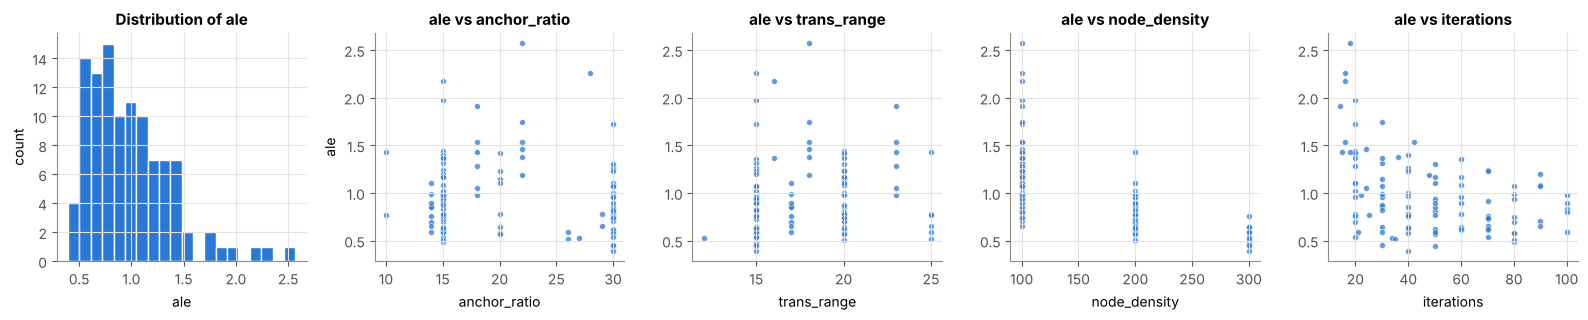

ale: min 0.39, median 0.90, max 2.57, skewness 1.31


,Spearman correlation with ale
anchor_ratio,-0.03
trans_range,0.21
node_density,-0.77
iterations,-0.40


In [4]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.3))
axes[0].hist(y, bins=20, color=BLUE, edgecolor="white")
axes[0].set(title="Distribution of ale", xlabel="ale", ylabel="count")
for ax, col in zip(axes[1:], FEATURES):
    ax.scatter(ale[col], y, s=18, color=BLUE, alpha=0.75, edgecolor="white", linewidth=0.5)
    ax.set(title=f"ale vs {col}", xlabel=col)
axes[1].set_ylabel("ale")
plt.tight_layout()
plt.show()

print(f"ale: min {y.min():.2f}, median {np.median(y):.2f}, max {y.max():.2f}, skewness {stats.skew(y):.2f}")
spearman = pd.Series({c: stats.spearmanr(ale[c], y)[0] for c in FEATURES}, name="Spearman correlation with ale")
spearman.round(2).to_frame()

**Observations.**

* `ale` is **right-skewed**: most values lie between 0.5 and 1.3, with a long tail up to 2.57 (skewness 1.31). A long
  right tail in the target often carries over into the residuals, so it is a first hint about the answer.
* `node_density` has the strongest relation with `ale` (Spearman −0.77: denser networks localize better), `iterations`
  a moderate negative one (−0.40), `trans_range` a weak positive one (0.21), and `anchor_ratio` essentially none.
* The features take only a few distinct values (`node_density` is 100, 200 or 300), as expected from a simulation grid.

## Step 3 · Build the models

| Model | Why include it | Preprocessing |
| --- | --- | --- |
| Linear regression | the model whose fitting criterion is squared error | none needed |
| Support vector regression, RBF kernel | smooth nonlinear fit | standardized features |
| Decision tree, maximum depth 4 | piecewise-constant fit that captures interactions; depth is limited so it cannot memorize 107 points | none needed |
| Neural network, two hidden layers of 32 units | flexible nonlinear fit | standardized features |

Standardization is placed inside a `Pipeline`, so in cross-validation the scaler is re-fit on each training fold and no
information from the held-out fold leaks into training.

In [5]:
models = {
    "Linear regression": LinearRegression(),
    "SVR (RBF kernel)": make_pipeline(StandardScaler(), SVR(kernel="rbf", C=10.0)),
    "Decision tree": DecisionTreeRegressor(max_depth=4, random_state=SEED),
    "Neural network": make_pipeline(
        StandardScaler(),
        MLPRegressor(hidden_layer_sizes=(32, 32), max_iter=5000, random_state=SEED)),
}
print("models:", ", ".join(models))

models: Linear regression, SVR (RBF kernel), Decision tree, Neural network


## Step 4 · Out-of-fold predictions and model evaluation

`cross_val_predict` with 5 folds trains each model on 80% of the data and predicts the remaining 20%, rotating
through the folds. Every observation therefore gets one prediction from a model that never saw it. These predictions
give honest accuracy metrics and honest residuals $r_i = y_i - \hat y_i$.

In [6]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

oof_pred, residuals, metrics = {}, {}, []
for name, model in models.items():
    pred = cross_val_predict(model, X, y, cv=cv)    # out-of-fold predictions
    oof_pred[name] = pred
    residuals[name] = y - pred
    metrics.append({"model": name,
                    "MAE": mean_absolute_error(y, pred),
                    "RMSE": np.sqrt(mean_squared_error(y, pred)),
                    "R^2": r2_score(y, pred)})

metrics = pd.DataFrame(metrics).set_index("model")
metrics.round(3)

,MAE,RMSE,R^2
model,,,
Linear regression,0.185,0.257,0.600
SVR (RBF kernel),0.151,0.200,0.758
Decision tree,0.190,0.263,0.581
Neural network,0.167,0.246,0.632


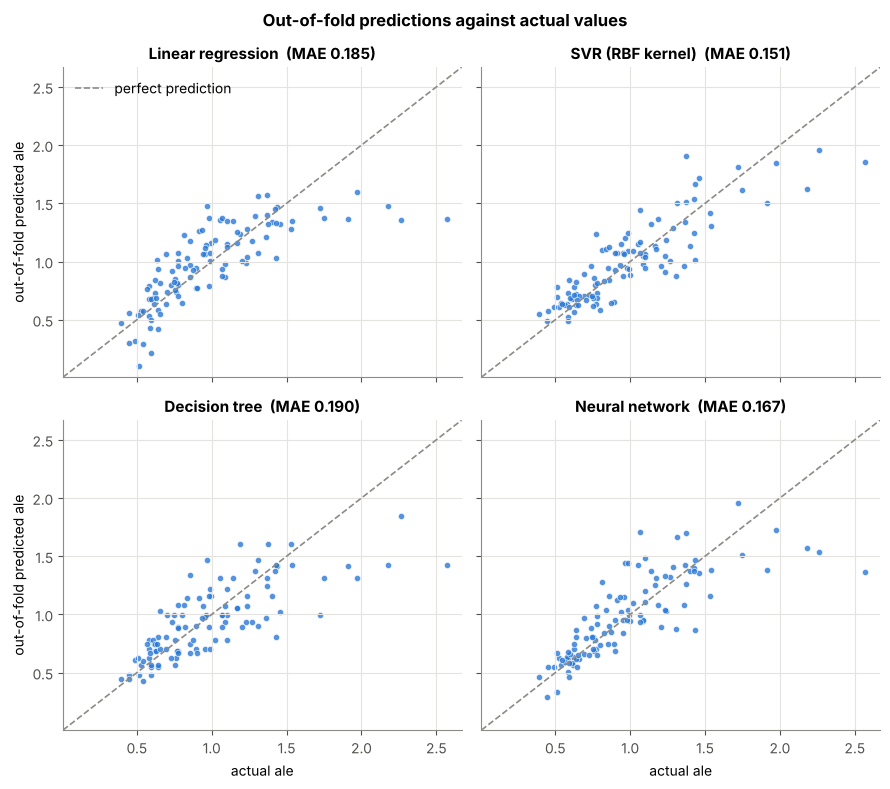

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(9, 8), sharex=True, sharey=True)
lo = min(y.min(), min(p.min() for p in oof_pred.values())) - 0.1
hi = max(y.max(), max(p.max() for p in oof_pred.values())) + 0.1
lims = [lo, hi]
for ax, (name, pred) in zip(axes.ravel(), oof_pred.items()):
    ax.plot(lims, lims, color=GREY, ls="--", lw=1.2, label="perfect prediction")
    ax.scatter(y, pred, s=20, color=BLUE, alpha=0.8, edgecolor="white", linewidth=0.5)
    ax.set(title=f"{name}  (MAE {metrics.loc[name, 'MAE']:.3f})", xlim=lims, ylim=lims)
for ax in axes[1]:
    ax.set_xlabel("actual ale")
for ax in axes[:, 0]:
    ax.set_ylabel("out-of-fold predicted ale")
axes[0, 0].legend(loc="upper left")
fig.suptitle("Out-of-fold predictions against actual values", fontweight="bold")
plt.tight_layout()
plt.show()

**Observations.** SVR is the most accurate model (lowest MAE and highest $R^2$), followed by the neural network. In
every panel the points with the largest actual `ale` fall **below** the diagonal: the models under-predict the
largest errors. Those points will become the large positive residuals examined next.

## Step 5 · Visual diagnostics of the residuals

**How to read a QQ plot.** The sorted residuals are plotted against the quantiles a standard normal sample of the same
size would have. If the residuals are normal, the points lie on a straight line (the dashed least-squares line).
An upper tail that bends **above** the line means a heavier right tail than the normal; a lower tail that bends
above the line means a shorter left tail. Together these are the signature of right skew.

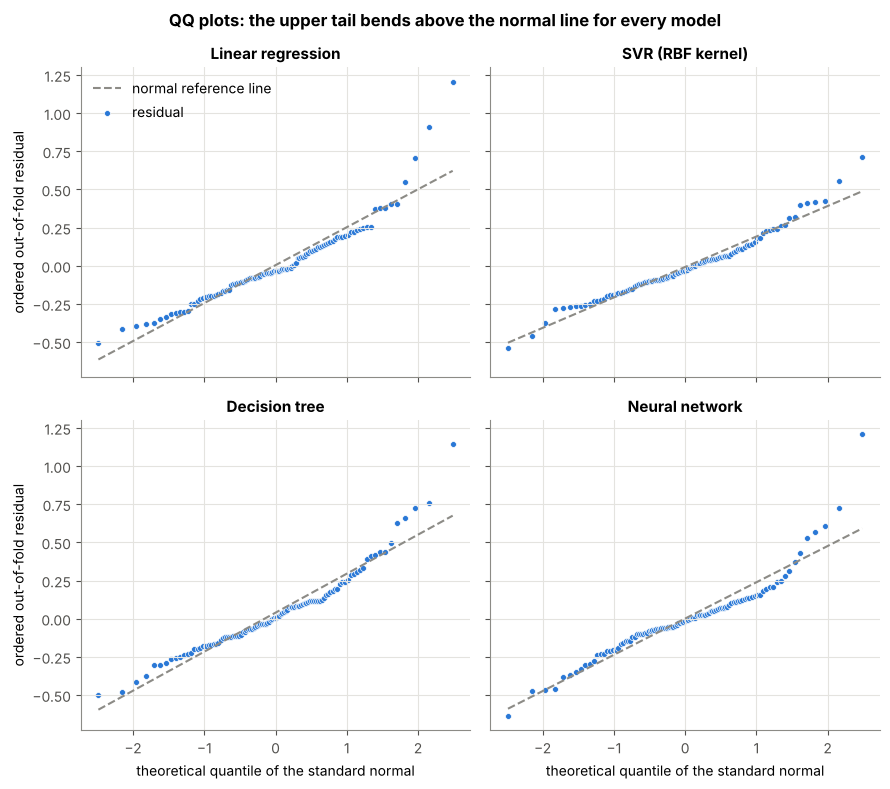

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(9, 8), sharex=True, sharey=True)
for ax, (name, r) in zip(axes.ravel(), residuals.items()):
    (theoretical, ordered), (slope, intercept, _) = stats.probplot(r, dist="norm")
    ax.plot(theoretical, intercept + slope * theoretical, color=GREY, ls="--", lw=1.5, label="normal reference line")
    ax.scatter(theoretical, ordered, s=18, color=BLUE, edgecolor="white", linewidth=0.5, label="residual")
    ax.set_title(name)
for ax in axes[1]:
    ax.set_xlabel("theoretical quantile of the standard normal")
for ax in axes[:, 0]:
    ax.set_ylabel("ordered out-of-fold residual")
axes[0, 0].legend(loc="upper left")
fig.suptitle("QQ plots: the upper tail bends above the normal line for every model", fontweight="bold")
plt.tight_layout()
plt.show()

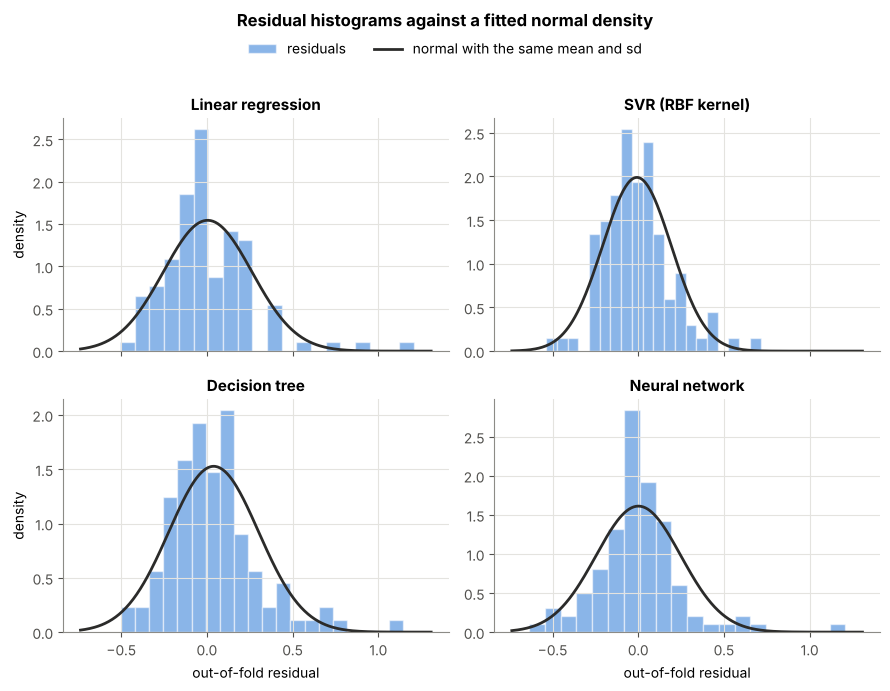

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(9, 7), sharex=True)
grid = np.linspace(min(r.min() for r in residuals.values()) - 0.1,
                   max(r.max() for r in residuals.values()) + 0.1, 300)
for ax, (name, r) in zip(axes.ravel(), residuals.items()):
    ax.hist(r, bins=20, density=True, color=BLUE, alpha=0.55, edgecolor="white", label="residuals")
    ax.plot(grid, stats.norm.pdf(grid, loc=r.mean(), scale=r.std(ddof=1)), color=INK, lw=2,
            label="normal with the same mean and sd")
    ax.set_title(name)
for ax in axes[1]:
    ax.set_xlabel("out-of-fold residual")
for ax in axes[:, 0]:
    ax.set_ylabel("density")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 0.955))
fig.suptitle("Residual histograms against a fitted normal density", fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

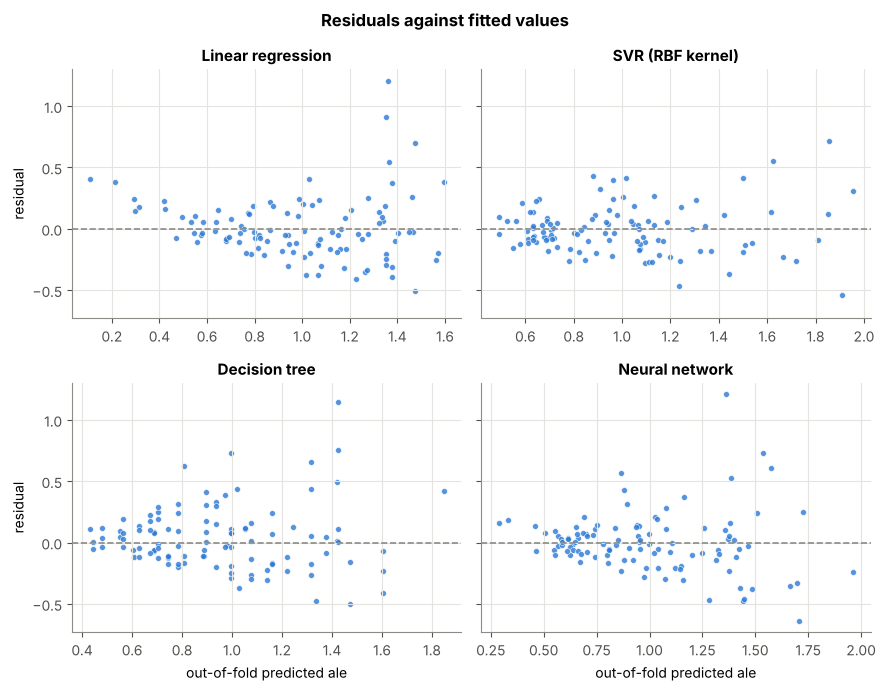

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(9, 7), sharey=True)
for ax, (name, r) in zip(axes.ravel(), residuals.items()):
    ax.axhline(0, color=GREY, ls="--", lw=1.2)
    ax.scatter(oof_pred[name], r, s=18, color=BLUE, alpha=0.8, edgecolor="white", linewidth=0.5)
    ax.set_title(name)
for ax in axes[1]:
    ax.set_xlabel("out-of-fold predicted ale")
for ax in axes[:, 0]:
    ax.set_ylabel("residual")
fig.suptitle("Residuals against fitted values", fontweight="bold")
plt.tight_layout()
plt.show()

**Observations.**

* **QQ plots:** the middle of each distribution follows the line, but the upper tail bends sharply above it for linear
  regression, the tree and the network, and more mildly for SVR. The largest residuals (about 1.2) are far larger than a
  normal sample of size 107 would produce.
* **Histograms:** the residuals are more peaked than the fitted normal near zero and have a long right tail.
* **Residuals vs fitted:** the largest positive residuals occur at larger predicted values, where the residuals also
  spread out more. For linear regression the residuals curve (positive at both ends of the fitted range), a sign that
  the linear model misses some nonlinearity, which adds to its skewness.

## Step 6 · Formal normality tests

For each model we test $H_0$: *the residuals are drawn from a normal distribution*.

* `scipy.stats.normaltest` (D'Agostino–Pearson $K^2$) combines the sample skewness and kurtosis, both of which are 0 for
  a normal distribution (kurtosis reported as *excess* kurtosis).
* `scipy.stats.shapiro` (Shapiro–Wilk) is a second, widely used test with good power at this sample size.

A p-value below 0.05 rejects normality at the 5% level. A large p-value would only mean "no evidence against
normality", not proof of it.

In [11]:
ALPHA = 0.05
rows = []
for name, r in residuals.items():
    _, p_dagostino = stats.normaltest(r)
    _, p_shapiro = stats.shapiro(r)
    rows.append({"model": name,
                 "skewness": stats.skew(r),
                 "excess kurtosis": stats.kurtosis(r),
                 "normaltest p-value": p_dagostino,
                 "Shapiro-Wilk p-value": p_shapiro,
                 "normal at 5%?": "rejected" if max(p_dagostino, p_shapiro) < ALPHA else "not rejected"})
tests = pd.DataFrame(rows).set_index("model")

# p-values span many orders of magnitude, so show them in scientific notation
tests_display = tests.copy()
for col in ["normaltest p-value", "Shapiro-Wilk p-value"]:
    tests_display[col] = tests[col].map(lambda p: f"{p:.2g}")
tests_display.round(2)

,skewness,excess kurtosis,normaltest p-value,Shapiro-Wilk p-value,normal at 5%?
model,,,,,
Linear regression,1.46,4.50,3e-10,1.8e-06,rejected
SVR (RBF kernel),0.65,1.38,0.0017,0.01,rejected
Decision tree,1.13,2.67,4.5e-07,6.3e-05,rejected
Neural network,1.26,5.18,1.2e-09,1.5e-06,rejected


**Result.** Every model's residuals have positive skewness (0.65 to 1.46) and positive excess kurtosis (1.4 to 5.2),
and both tests reject normality for every model, all with p < 0.011. SVR comes closest to normal but is still rejected.
With only 107 observations these tests are not over-powered, so p-values as small as $10^{-10}$ reflect real
departures, which the QQ plots confirm.

## Step 7 · Why out-of-fold residuals matter

For comparison, refit each model on all the data and test its **in-sample** (training) residuals.

In [12]:
rows = []
for name, model in models.items():
    model.fit(X, y)
    r_in = y - model.predict(X)
    rows.append({"model": name,
                 "in-sample MAE": np.abs(r_in).mean(),
                 "out-of-fold MAE": metrics.loc[name, "MAE"],
                 "in-sample normaltest p": f"{stats.normaltest(r_in)[1]:.2g}",
                 "out-of-fold normaltest p": f"{tests.loc[name, 'normaltest p-value']:.2g}"})
pd.DataFrame(rows).set_index("model").round(3)

,in-sample MAE,out-of-fold MAE,in-sample normaltest p,out-of-fold normaltest p
model,,,,
Linear regression,0.167,0.185,1.3e-09,3e-10
SVR (RBF kernel),0.101,0.151,0.00018,0.0017
Decision tree,0.116,0.190,0.38,4.5e-07
Neural network,0.132,0.167,3e-08,1.2e-09


In-sample errors are smaller than out-of-fold errors for every flexible model, and the **decision tree's in-sample
residuals pass the normality test (p ≈ 0.38) while its out-of-fold residuals fail it (p ≈ 5 × 10⁻⁷)**. A tree fits
the training points it splits on, which trims the tail; testing training residuals would have led to the wrong
conclusion.

## Conclusion

**The residuals are not approximately normal.** For all four models (linear regression, SVR, decision tree, neural
network) the out-of-fold residuals are right-skewed and heavy-tailed: the QQ plots bend above the normal line in the
upper tail, and both the D'Agostino–Pearson and Shapiro–Wilk tests reject normality at the 1% level. The models
occasionally **under-predict** `ale` by a large amount, which is consistent with the right-skewed target.

**What this means for squared error.** The justification "residuals are normal, so maximum likelihood gives squared
error" does not hold on this dataset. Squared error still estimates the conditional mean $E[Y \mid x]$, but a few large
positive residuals have outsized influence on a squared loss. A heavier-tailed likelihood such as the Student-t
(Question 5, regression part (b)) is a natural alternative.